# 03 Clock drift between the 100 Hz (sleep-lab) file and the 64 Hz (wristband) file

S042, S022, S035. Convention: `t64 = t100 + offset`.

1. **Label offset:** the constant offset that lines up the stage labels of the two files.
2. **Internal check:** inside the 100 Hz file, are ECG R-peaks locked to the file's own BVP copy? (offset searched near 0)
3. **Drift:** in 5-minute windows across the night, the offset at which our 64 Hz PPG beats lock to the ECG R-peaks. A straight line means simple clock drift.

In [1]:
import os
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT / "src")); sys.path.insert(0, str(PROJECT / "qc"))
from qc_funcs import load_wristband
from preprocess import find_wristband_files, filter_bvp
from beats import detect_beats, ecg_rpeaks, label_offset, local_lock_offset
DATA_ROOT = Path(os.environ.get("DREAMT_ROOT", PROJECT / "data" / "raw"))
D100 = DATA_ROOT / "physionet.org/files/dreamt/2.2.0/data_100Hz"
FIG_DIR = PROJECT / "notebooks" / "figs"
plt.rcParams.update({"font.size": 8})
files = find_wristband_files(DATA_ROOT)
SUBJECTS = ["S042", "S022", "S035"]

In [2]:
S, rows = {}, []
for s in SUBJECTS:
    _, w = load_wristband(files[s])
    p = pd.read_csv(D100 / f"{s}_PSG_df.csv", usecols=["TIMESTAMP", "ECG", "BVP", "Sleep_Stage"])
    t64, t100 = w.TIMESTAMP.to_numpy(), p.TIMESTAMP.to_numpy()
    _, pt = detect_beats(filter_bvp(w.BVP.to_numpy()))
    pt = pt + t64[0]
    _, rt = ecg_rpeaks(p.ECG.to_numpy()); rt = rt + t100[0]
    _, bt = detect_beats(filter_bvp(p.BVP.to_numpy(), fs=100), fs=100); bt = bt + t100[0]
    lo, share = label_offset(p.Sleep_Stage.astype(str).to_numpy(), t100, w.Sleep_Stage.astype(str).to_numpy(), t64)
    S[s] = dict(pt=pt, rt=rt, bt=bt, t100=t100, label_off=lo)
    rows.append({"subject": s, "label_offset_s": lo, "label_changes_matched": share,
                 "ecg_beats": len(rt), "ppg64_beats": len(pt), "bvp100_beats": len(bt)})
    print(s, "done", flush=True)
print(pd.DataFrame(rows).set_index("subject").to_string())

S042 done


S022 done


S035 done


         label_offset_s  label_changes_matched  ecg_beats  ppg64_beats  bvp100_beats
subject                                                                             
S042             8580.0                    1.0      31931        43254         31851
S022             2145.0                    1.0      23055        34522         25378
S035                0.0                    1.0      24069        38477         24397


## Internal check: ECG vs the BVP copy inside the 100 Hz file

In [3]:
rows = []
for s, d in S.items():
    t = d["t100"]
    for c in np.linspace(t[0] + 600, t[-1] - 900, 6):
        res = local_lock_offset(d["rt"], d["bt"], np.arange(-2, 2, 0.01), c)
        rows.append({"subject": s, "t100": c, **res})
internal = pd.DataFrame(rows)
print(internal.round(3).to_string(index=False))

subject      t100  offset_s  lock_share  delay_s  n_ref
   S042   630.000      1.41       0.151    0.365    371
   S042  4967.998      1.99       0.157    0.372    453
   S042  9305.996      1.64       0.183    0.339    388
   S042 13643.994      1.96       0.328    0.162    396
   S042 17981.992     -0.32       0.319    0.654    395
   S042 22319.990     -2.00       0.218    0.407    432
   S022  6090.000      1.64       0.129    0.341    279
   S022 10883.998     -1.15       0.096    0.536    281
   S022 15677.996     -0.95       0.114    0.445    307
   S022 20471.994      1.67       0.237    0.791    279
   S022 25265.992     -2.00       0.149    0.798    248
   S022 30059.990     -1.54       0.138    0.328    269
   S035 11730.000      0.79       0.143    0.478    357
   S035 15624.198      1.09       0.124    0.405    355
   S035 19518.396      1.56       0.237    0.177    334
   S035 23412.594      1.25       0.200    0.205    335
   S035 27306.792      0.89       0.243    0.268

## Drift: 64 Hz PPG beats vs ECG, 5-minute windows

In [4]:
rows = []
for s, d in S.items():
    t = d["t100"]
    offs = np.arange(d["label_off"] - 30, d["label_off"] + 90, 0.01)
    for c in np.linspace(t[0] + 600, t[-1] - 900, 12):
        res = local_lock_offset(d["rt"], d["pt"], offs, c)
        rows.append({"subject": s, "t100": c, **res})
    print(s, "done", flush=True)
drift = pd.DataFrame(rows)
print(drift.round(3).to_string(index=False))

S042 done


S022 done


S035 done


subject      t100  offset_s  lock_share  delay_s  n_ref
   S042   630.000   8594.38       0.555    0.541    371
   S042  2601.817   8596.95       0.763    0.565    405
   S042  4573.635   8600.42       0.387    0.360    445
   S042  6545.452   8602.90       0.790    0.163    410
   S042  8517.269   8605.29       0.573    0.547    403
   S042 10489.086   8607.56       0.312    0.366    400
   S042 12460.904   8610.37       0.745    0.142    435
   S042 14432.721   8612.07       0.416    0.355    418
   S042 16404.538   8614.64       0.723    0.400    404
   S042 18376.355   8617.65       0.365    0.351    408
   S042 20348.173   8619.76       0.394    0.488    436
   S042 22319.990   8622.71       0.544    0.346    432
   S022  6090.000   2158.69       0.376    0.327    279
   S022  8269.090   2161.08       0.372    0.830    282
   S022 10448.180   2164.84       0.218    0.445    280
   S022 12627.270   2167.11       0.286    0.760    287
   S022 14806.360   2170.13       0.228    0.721

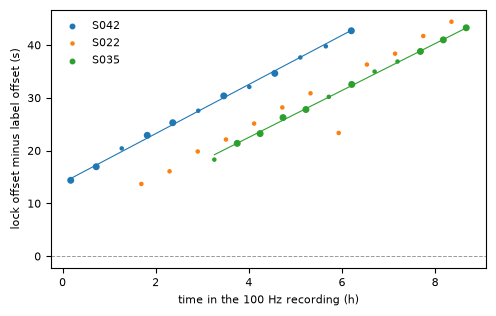

         n_good_windows  drift_ppm  offset_at_start_s  max_resid_ms  label_offset_s  label_misalign_start_s
subject                                                                                                    
S042                  7   1293.857           8594.721       525.000          8580.0                  14.721
S035                  8   1233.705             19.223       485.362             0.0                  19.223


In [5]:
fit_rows = []
fig, ax = plt.subplots(figsize=(5, 3.2))
for s, g in drift.groupby("subject", sort=False):
    good = g[g.lock_share >= 0.5]
    h = ax.scatter(g.t100 / 3600, g.offset_s - S[s]["label_off"], s=np.where(g.lock_share >= 0.5, 16, 5), label=s)
    if len(good) >= 3:
        b, a = np.polyfit(good.t100, good.offset_s, 1)
        resid = good.offset_s - (a + b * good.t100)
        x = np.array([g.t100.min(), g.t100.max()])
        ax.plot(x / 3600, a + b * x - S[s]["label_off"], color=h.get_facecolor()[0], lw=0.8)
        fit_rows.append({"subject": s, "n_good_windows": len(good), "drift_ppm": b * 1e6,
                         "offset_at_start_s": a + b * g.t100.min(), "max_resid_ms": 1000 * np.abs(resid).max(),
                         "label_offset_s": S[s]["label_off"]})
ax.axhline(0, color="0.6", lw=0.7, ls="--")
ax.set_xlabel("time in the 100 Hz recording (h)")
ax.set_ylabel("lock offset minus label offset (s)")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig_clock_drift.png", dpi=150); plt.show()
fit = pd.DataFrame(fit_rows).set_index("subject")
fit["label_misalign_start_s"] = fit.offset_at_start_s - fit.label_offset_s
print(fit.round(3).to_string())